* `Import Liberaries`

In [74]:
import numpy as np
import pandas as pd
import re
import os
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

import seaborn as sns
from imblearn.over_sampling import SMOTE

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import word_tokenize

from wordcloud import WordCloud
import spacy
import gensim.downloader as api
from gensim.models import Word2Vec
from tqdm import tqdm

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\eyad0\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\eyad0\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\eyad0\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\eyad0\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

* `Read Dataset`

In [75]:
FILE_PATH = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'SRC' ,'Data', 'testdata.manual.2009.06.14.csv')
df = pd.read_csv(FILE_PATH)

In [76]:
df.head()

,target,ids,date,flag,user,text
0,4,3,Mon May 11 03:17:40 UTC 2009,kindle2,tpryan,@stellargirl I loooooooovvvvvveee my Kindle2. ...
1,4,4,Mon May 11 03:18:03 UTC 2009,kindle2,vcu451,Reading my kindle2... Love it... Lee childs i...
2,4,5,Mon May 11 03:18:54 UTC 2009,kindle2,chadfu,"Ok, first assesment of the #kindle2 ...it fuck..."
3,4,6,Mon May 11 03:19:04 UTC 2009,kindle2,SIX15,@kenburbary You'll love your Kindle2. I've had...
4,4,7,Mon May 11 03:21:41 UTC 2009,kindle2,yamarama,@mikefish Fair enough. But i have the Kindle2...


* `EDA`

In [77]:
df.shape

(498, 6)

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 498 entries, 0 to 497
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   target  498 non-null    int64 
 1   ids     498 non-null    int64 
 2   date    498 non-null    object
 3   flag    498 non-null    object
 4   user    498 non-null    object
 5   text    498 non-null    object
dtypes: int64(2), object(4)
memory usage: 23.5+ KB


In [79]:
df['target'].value_counts(normalize=True) 
                                                # 0 => -ve
                                                # 2 => nutral
                                                # 4 => +ve 
                              
## No sequence in encoding
## Little unbalanced

target
4    0.365462
0    0.355422
2    0.279116
Name: proportion, dtype: float64

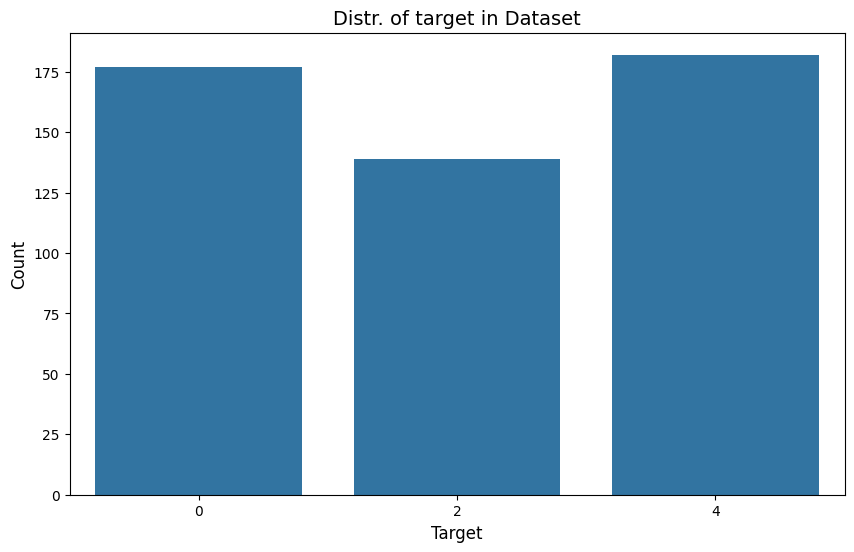

In [80]:
# Countplot Of target
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='target')
plt.title('Distr. of target in Dataset', fontsize=14, c='k')
plt.xlabel('Target', c='k', fontsize=12)
plt.ylabel('Count', c='k', fontsize=12)
plt.show()

In [81]:
## Take Only target and text from dataset
dataset = df[['target', 'text']]
dataset

,target,text
0,4,@stellargirl I loooooooovvvvvveee my Kindle2. ...
1,4,Reading my kindle2... Love it... Lee childs i...
2,4,"Ok, first assesment of the #kindle2 ...it fuck..."
3,4,@kenburbary You'll love your Kindle2. I've had...
4,4,@mikefish Fair enough. But i have the Kindle2...
...,...,...
493,2,Ask Programming: LaTeX or InDesign?: submitted...
494,0,"On that note, I hate Word. I hate Pages. I hat..."
495,4,Ahhh... back in a *real* text editing environm...
496,0,"Trouble in Iran, I see. Hmm. Iran. Iran so far..."


* `Text Cleaning & Visualization`

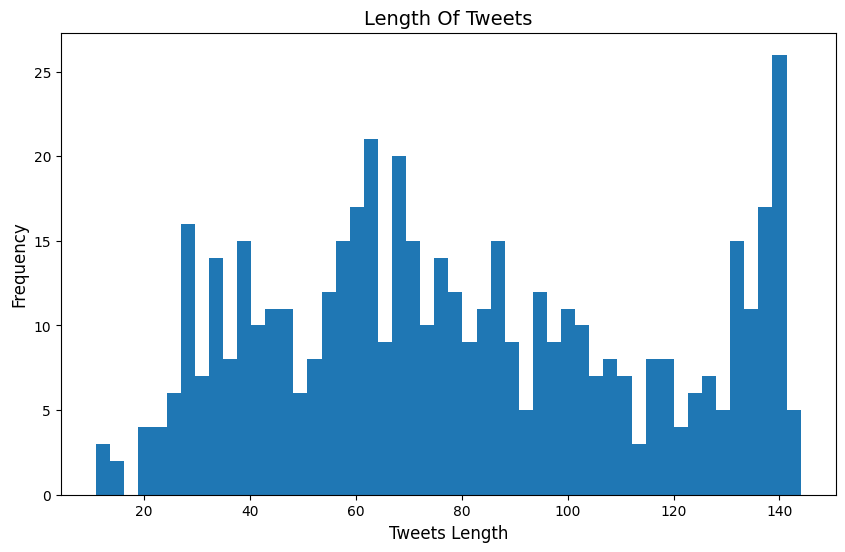

In [82]:
length_tweets = dataset['text'].str.len()

# Histogram of length of tweets
plt.figure(figsize=(10, 6))
plt.hist(length_tweets, bins=50)
plt.title('Length Of Tweets', fontsize=14, c='k')
plt.xlabel('Tweets Length', c='k', fontsize=12)
plt.ylabel('Frequency', c='k', fontsize=12)
plt.show()

In [83]:
# Hashtags
def hashtag_extract(x):
    hashtags = []
    # Loop over the words in the tweet
    for i in x:
        ht = re.findall(r"#(\w+)", i)
        hashtags.append(ht)
        
    return hashtags
        
        
# Apply function to extract hashtags from tweets but for each class
hash_neg = hashtag_extract(dataset['text'][dataset['target'] == 0])
hash_pos = hashtag_extract(dataset['text'][dataset['target'] == 4])
hash_neu = hashtag_extract(dataset['text'][dataset['target'] == 2])

# Unnesting
hash_neg = sum(hash_neg, [])
hash_pos = sum(hash_pos, [])
hash_neu = sum(hash_neu, [])

In [84]:
list(nltk.FreqDist(hash_neg).values())

[1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

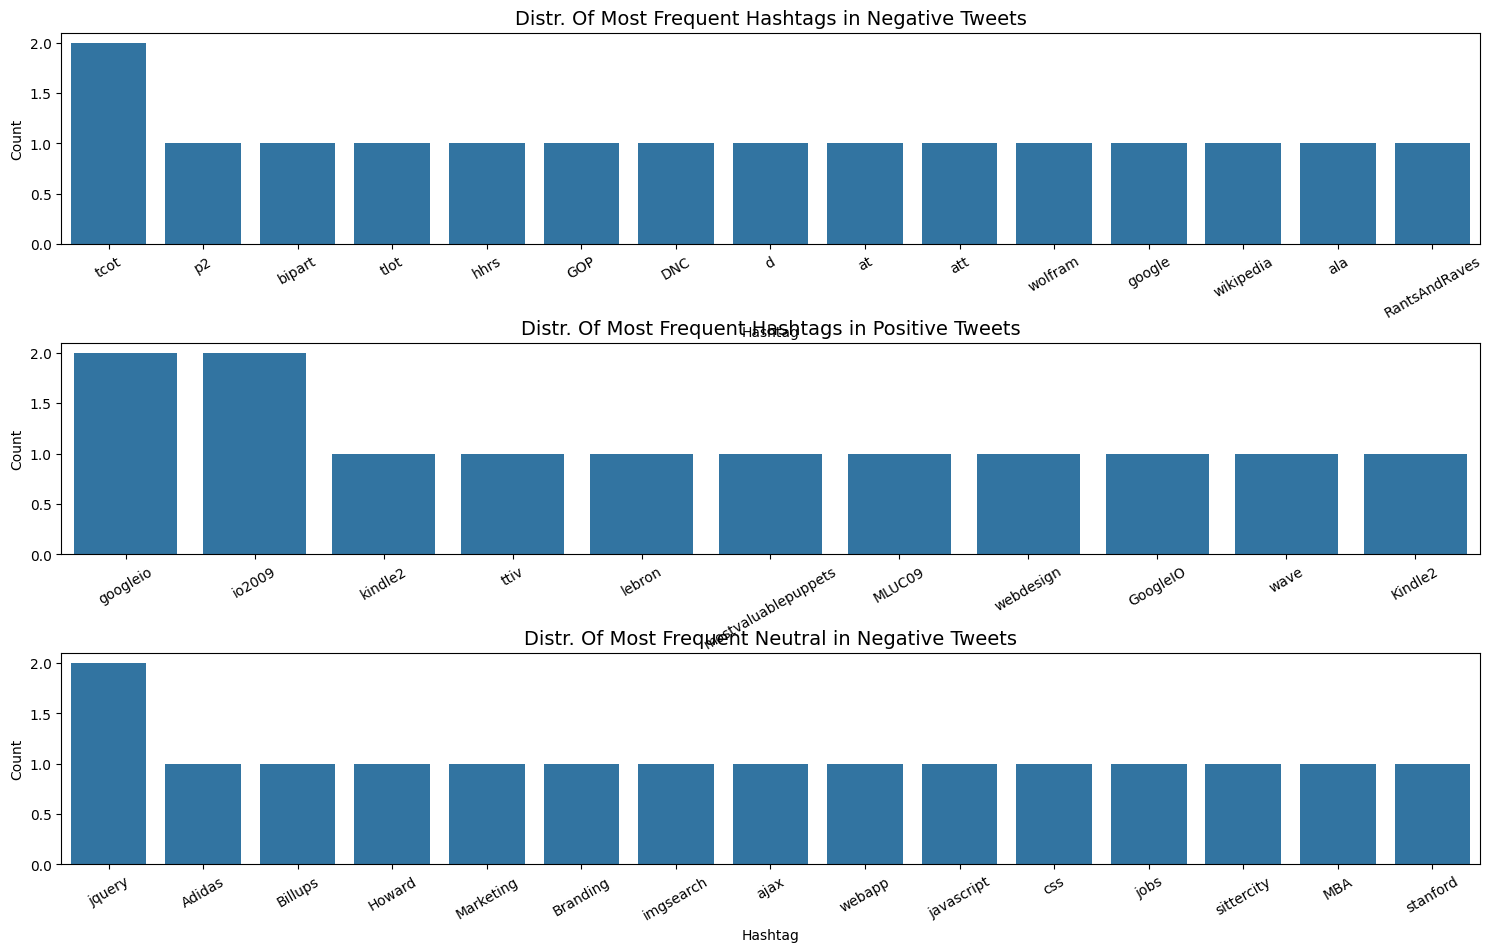

In [85]:
a_neg = nltk.FreqDist(hash_neg)
a_pos = nltk.FreqDist(hash_pos)
a_neu = nltk.FreqDist(hash_neu)

# Negative Tweets
df_neg = pd.DataFrame({'Hashtag': list(a_neg.keys()),
                       'Count': list(a_neg.values())})

# Positive Tweets
df_pos = pd.DataFrame({'Hashtag': list(a_pos.keys()),
                       'Count': list(a_pos.values())})

# Neutral Tweets
df_neu = pd.DataFrame({'Hashtag': list(a_neu.keys()),
                       'Count': list(a_neu.values())})

# Selecting top 15 most frequent hashtags
df_neg = df_neg.nlargest(columns='Count', n=15)
df_pos = df_pos.nlargest(columns='Count', n=15)
df_neu = df_neu.nlargest(columns='Count', n=15)

# Plotting
fig, ax = plt.subplots(3, 1, figsize=(16, 10))
fig.tight_layout(pad=5)
plt.sca(ax[0])
sns.barplot(data=df_neg, x='Hashtag', y='Count')
plt.xticks(rotation=30)
plt.title('Distr. Of Most Frequent Hashtags in Negative Tweets', fontsize=14, c='k')

plt.sca(ax[1])
sns.barplot(data=df_pos, x='Hashtag', y='Count')
plt.xticks(rotation=30)
plt.title('Distr. Of Most Frequent Hashtags in Positive Tweets', fontsize=14, c='k')

plt.sca(ax[2])
sns.barplot(data=df_neu, x='Hashtag', y='Count')
plt.xticks(rotation=30)
plt.title('Distr. Of Most Frequent Neutral in Negative Tweets', fontsize=14, c='k')
plt.show()

* `Hashtag hasn't a relation with sentiment ---> (Redundunt)`` 

In [86]:
# Function to remove unwanted patterns from the tweets
def remove_pattern(input_txt, pattern):
    return re.sub(pattern, '', input_txt)

* `Remove Tags`

In [87]:
# Check before
dataset['text'].iloc[493]

'Ask Programming: LaTeX or InDesign?: submitted by calcio1 [link] [1 comment] http://tinyurl.com/myfmf7'

In [88]:
dataset.loc[:, 'text'] = dataset['text'].apply(lambda x: remove_pattern(x, r'@[\w]*'))
dataset.head()

,target,text
0,4,I loooooooovvvvvveee my Kindle2. Not that the...
1,4,Reading my kindle2... Love it... Lee childs i...
2,4,"Ok, first assesment of the #kindle2 ...it fuck..."
3,4,You'll love your Kindle2. I've had mine for a...
4,4,Fair enough. But i have the Kindle2 and I th...


* `Remove Hyperlink`

In [89]:
# Remove Hyperlink
dataset.loc[:, 'text'] = dataset['text'].apply(lambda x: remove_pattern(x, r'https?://\S+|www\.\S+'))
dataset.head()

,target,text
0,4,I loooooooovvvvvveee my Kindle2. Not that the...
1,4,Reading my kindle2... Love it... Lee childs i...
2,4,"Ok, first assesment of the #kindle2 ...it fuck..."
3,4,You'll love your Kindle2. I've had mine for a...
4,4,Fair enough. But i have the Kindle2 and I th...


In [90]:
# Check After
dataset['text'].iloc[493]

'Ask Programming: LaTeX or InDesign?: submitted by calcio1 [link] [1 comment] '

* `Remove Repeated Chars`

In [91]:
# Check before
dataset['text'].iloc[0]

' I loooooooovvvvvveee my Kindle2. Not that the DX is cool, but the 2 is fantastic in its own right.'

- Assume more than 2 same seq chars is typo

In [92]:
# A Function to remove excessive repeated chars while preserving correct words
def remove_excessive_repeated_chars(input_str, max_repeats=2):
    
    # Define a regular expression pattern to match consecutive repeated chars
    pattern = f"(\\w)\\1{{{max_repeats},}}"
    
    # Replace the matched pattern with a single occurance of the char
    cleaned_string = re.sub(pattern, r"\1", input_str)
    
    return cleaned_string

# Apply func
dataset.loc[:, 'text'] = dataset['text'].apply(lambda x: remove_excessive_repeated_chars(x))
dataset.head()


,target,text
0,4,"I love my Kindle2. Not that the DX is cool, b..."
1,4,Reading my kindle2... Love it... Lee childs i...
2,4,"Ok, first assesment of the #kindle2 ...it fuck..."
3,4,You'll love your Kindle2. I've had mine for a...
4,4,Fair enough. But i have the Kindle2 and I th...


In [93]:
# Check After
dataset['text'].iloc[0]

' I love my Kindle2. Not that the DX is cool, but the 2 is fantastic in its own right.'

* `Emotions`

In [94]:
# Check Before
dataset['text'].iloc[73]

'Back when I worked for Nike we had one fav word : JUST DO IT! :)'

- Map Emotions to it's text

In [95]:
emoticon_meanings = {
    ":)": "Happy",
    ":(": "Sad",
    ":D": "Very Happy",
    ":|": "Neutral",
    ":O": "Surprised",
    "<3": "Love",
    ";)": "Wink",
    ":P": "Playful",
    ":/": "Confused",
    ":*": "Kiss",
    ":')": "Touched",
    "XD": "Laughing",
    ":3": "Cute",
    ">:(": "Angry",
    ":-O": "Shocked",
    ":|]": "Robot",
    ":>": "Sly",
    "^_^": "Happy",
    "O_o": "Confused",
    ":-|": "Straight Face",
    ":X": "Silent",
    "B-)": "Cool",
    "<( '.' <)": "Dance",
    "(-_-)": "Bored",
    "(>_<)": "Upset",
    "(~_~)": "Sarcastic",
    "(o_o)": "Surprised",
    "(o.o)": "Shocked",
    ":0": "Shocked",
    ":*(": "Crying",
    ":v": "Pac-Man",
    "(^.^)v": "Double Victory",
    ":-D": "Big Grin",
    ":-*": "Blowing a Kiss",
    ":^)": "Nosey",
    ":-((": "Very Sad",
    ":-(": "Frowning",
}

In [96]:
def conver_emotions(text: str):
    
    for emotion, meaning in emoticon_meanings.items():
        text = text.replace(emotion, meaning)
        
    return text

# Apply func
dataset.loc[:, 'text'] = dataset['text'].apply(conver_emotions)
dataset.head()

,target,text
0,4,"I love my Kindle2. Not that the DX is cool, b..."
1,4,Reading my kindle2... Love it... Lee childs i...
2,4,"Ok, first assesment of the #kindle2 ...it fuck..."
3,4,You'll love your Kindle2. I've had mine for a...
4,4,Fair enough. But i have the Kindle2 and I th...


In [97]:
# Check After
dataset['text'].iloc[73]

'Back when I worked for Nike we had one fav word : JUST DO IT! Happy'

* `Remove puctuations, Numbers, Special Chars`

In [98]:
# Remove puctuations, Numbers, Special Chars
dataset.loc[:, 'text'] = dataset['text'].str.replace('[^a-zA-Z#]', ' ', regex=True)
dataset.head()

,target,text
0,4,I love my Kindle Not that the DX is cool b...
1,4,Reading my kindle Love it Lee childs i...
2,4,Ok first assesment of the #kindle it fuck...
3,4,You ll love your Kindle I ve had mine for a...
4,4,Fair enough But i have the Kindle and I th...


* `Short Words`

In [99]:
dataset.loc[:, 'text'] = dataset['text'].apply(lambda x: ' '.join([w for w in x.split() if len(w) > 3]))
dataset.head()

,target,text
0,4,love Kindle that cool fantastic right
1,4,Reading kindle Love childs good read
2,4,first assesment #kindle fucking rocks
3,4,love your Kindle mine months never looked back...
4,4,Fair enough have Kindle think perfect Happy


* `Removing Numbers`

In [100]:
# Remove Numbers Completly From Dataset
dataset.loc[:, 'text'] = dataset['text'].apply(lambda x: remove_pattern(x, '[^\w\s]'))
dataset.head()

,target,text
0,4,love Kindle that cool fantastic right
1,4,Reading kindle Love childs good read
2,4,first assesment kindle fucking rocks
3,4,love your Kindle mine months never looked back...
4,4,Fair enough have Kindle think perfect Happy


* `Remove Special Chars`

In [101]:
# Remove Numbers Completly From Dataset
dataset.loc[:, 'text'] = dataset['text'].apply(lambda x: remove_pattern(x, r'[!@#$%^&*()_+{}\[\]:;<>,.?~\\|\/]'))
dataset.head()

,target,text
0,4,love Kindle that cool fantastic right
1,4,Reading kindle Love childs good read
2,4,first assesment kindle fucking rocks
3,4,love your Kindle mine months never looked back...
4,4,Fair enough have Kindle think perfect Happy


* `Redundant words`

In [102]:
# Remove Redundant words like (I've, You'll)
# Challenging

def remove_redundant_words_extra_spaces(text: str):
    
    # Remove Contractions
    contraction_pattern = re.compile(r"'\w+|\w+'\w+|\w+'")
    text = contraction_pattern.sub('', text)
    
    # Define a set of stopwords
    english_stopwords = set(stopwords.words('english'))
    
    # Remove stopwords and extra spaces
    words = text.split()
    filtered_words = [word for word in words if word.lower() not in english_stopwords]
    clean_text = ' '.join(filtered_words)
    
    # Remove extra spaces
    clean_text = ' '.join(clean_text.split())
    
    return clean_text


dataset.loc[:, 'text'] = dataset['text'].apply(remove_redundant_words_extra_spaces)
dataset.head()

,target,text
0,4,love Kindle cool fantastic right
1,4,Reading kindle Love childs good read
2,4,first assesment kindle fucking rocks
3,4,love Kindle mine months never looked back huge...
4,4,Fair enough Kindle think perfect Happy


In [103]:
# Make Folder For Cleaned Dataset

CLEANED_DATASET = os.path.join(os.getcwd(), 'cleaned-dataset')
os.makedirs(CLEANED_DATASET, exist_ok=True)

In [104]:
# Dump Cleaned Dataset
os.path.join(CLEANED_DATASET, 'cleaned_dataset_1.csv')

'c:\\Users\\eyad0\\Documents\\python\\Agoor\\Embedding_project\\SRC\\notebooks\\cleaned-dataset\\cleaned_dataset_1.csv'

* `Lemmatization`

* `1. Tokenization`

In [105]:
# Word Tokenize
tokenized_tweets = dataset['text'].apply(lambda x: word_tokenize(x))
tokenized_tweets.head()

0               [love, Kindle, cool, fantastic, right]
1          [Reading, kindle, Love, childs, good, read]
2           [first, assesment, kindle, fucking, rocks]
3    [love, Kindle, mine, months, never, looked, ba...
4        [Fair, enough, Kindle, think, perfect, Happy]
Name: text, dtype: object

In [106]:
# Lemmatizer
lemmatizer = WordNetLemmatizer()

tokenized_tweets = tokenized_tweets.apply(lambda x: [lemmatizer.lemmatize(i) for i in x])
 
# Join Words
dataset.loc[:, 'text'] = tokenized_tweets.apply(lambda x: ' '.join(x))
dataset.head()

,target,text
0,4,love Kindle cool fantastic right
1,4,Reading kindle Love child good read
2,4,first assesment kindle fucking rock
3,4,love Kindle mine month never looked back huge ...
4,4,Fair enough Kindle think perfect Happy


In [107]:
# Dump Lemmatized Dataset
os.path.join(CLEANED_DATASET, 'cleaned_dataset_2.csv')

'c:\\Users\\eyad0\\Documents\\python\\Agoor\\Embedding_project\\SRC\\notebooks\\cleaned-dataset\\cleaned_dataset_2.csv'

---

* `Text Visualization`

* `WordCloud`

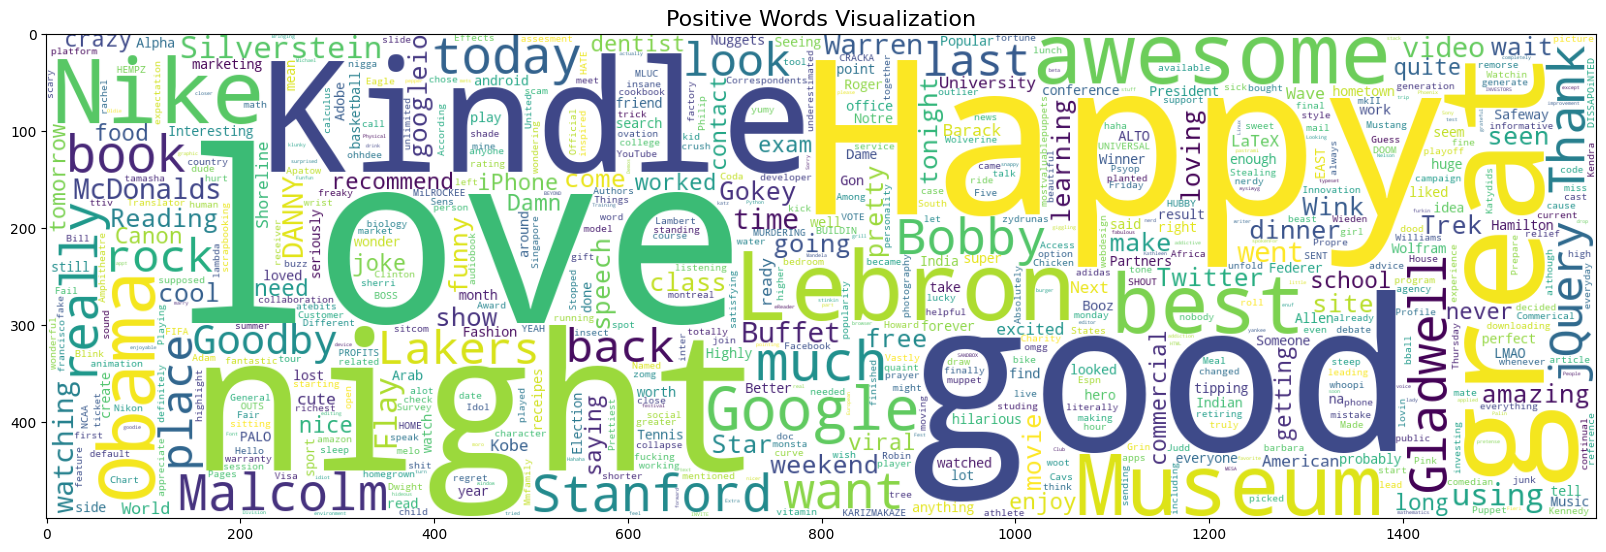

In [108]:
# For positive words
plt.figure(figsize=(20, 8))
wc = WordCloud(max_words=10000, width=1600, height=500, collocations=False, 
          background_color='white').generate(' '.join(dataset[dataset['target'] == 4]['text'].astype(str)))
plt.title('Positive Words Visualization', fontsize=16, c='k')
plt.imshow(wc)
plt.show()

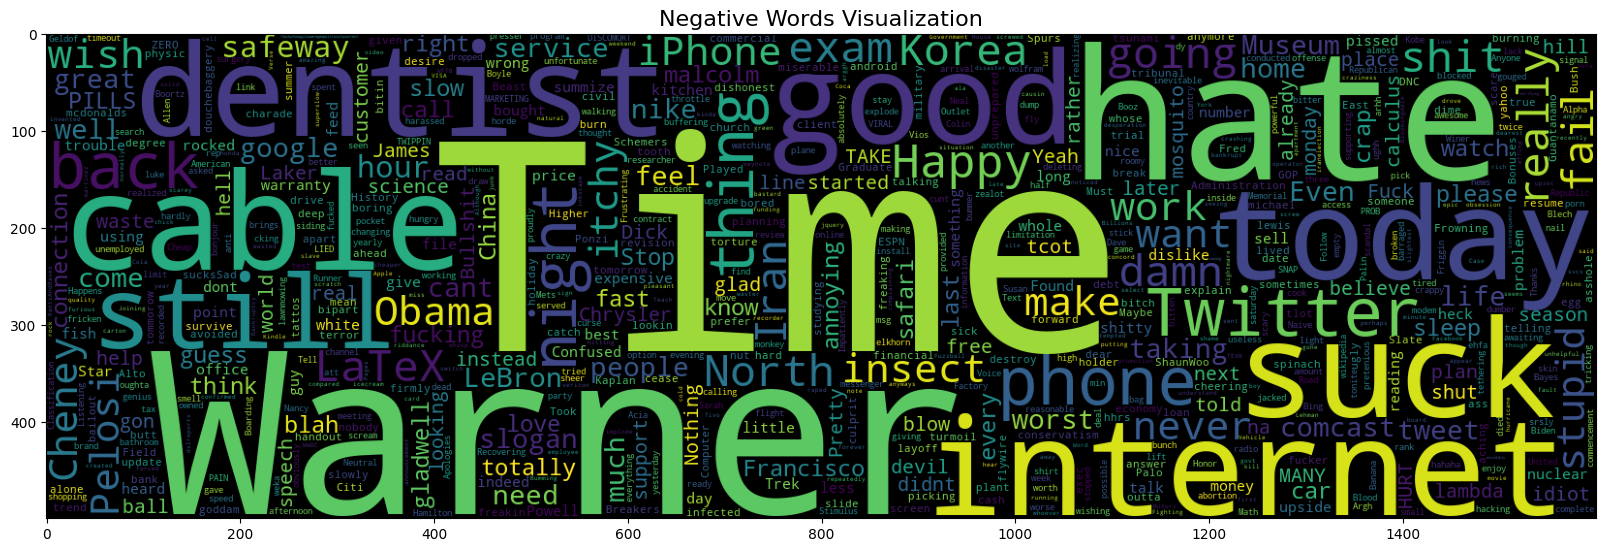

In [109]:
# For Negative words
plt.figure(figsize=(20, 8))
wc = WordCloud(max_words=10000, width=1600, height=500, collocations=False, 
          background_color='Black').generate(' '.join(dataset[dataset['target'] == 0]['text'].astype(str)))
plt.title('Negative Words Visualization', fontsize=16, c='k')
plt.imshow(wc)
plt.show()

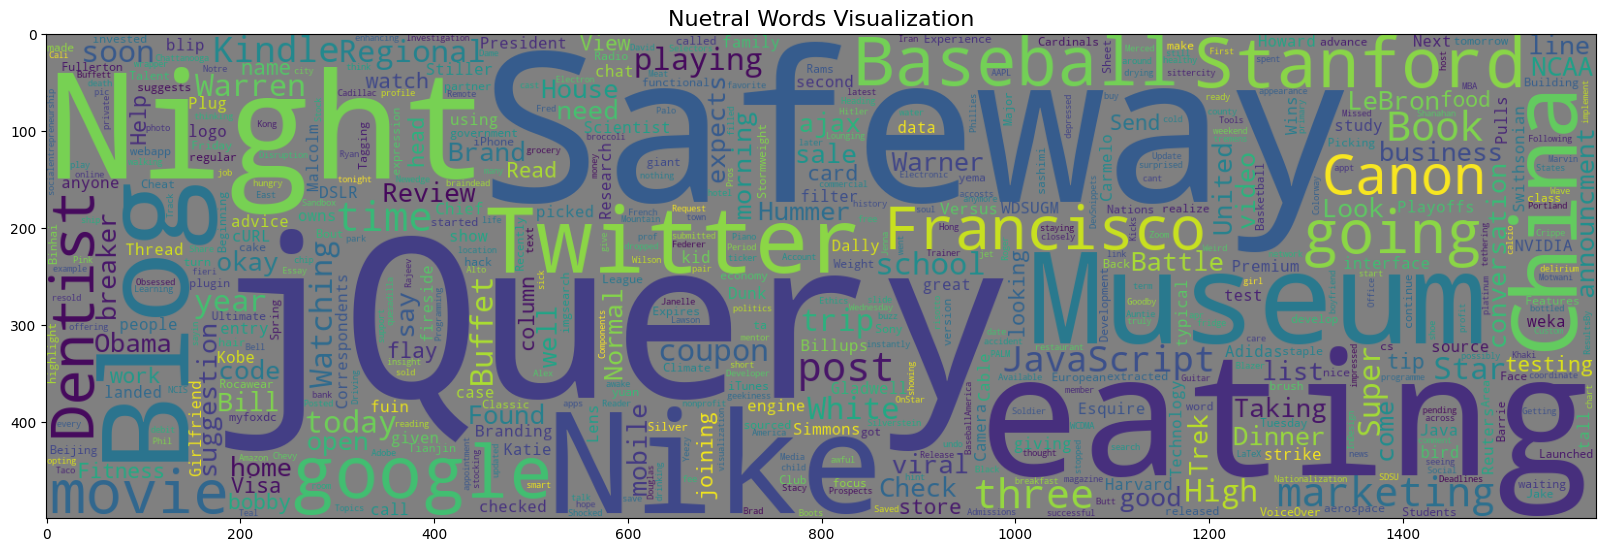

In [110]:
# For Nuetral words
plt.figure(figsize=(20, 8))
wc = WordCloud(max_words=10000, width=1600, height=500, collocations=False, 
          background_color='grey').generate(' '.join(dataset[dataset['target'] == 2]['text'].astype(str)))
plt.title('Nuetral Words Visualization', fontsize=16, c='k')
plt.imshow(wc)
plt.show()

---

* `Text Vectorization`

* 1. BOW

In [111]:
# BOW
bow_vecorizer = CountVectorizer(max_df=0.09, min_df=2, max_features=None, stop_words='english')
X_bow = bow_vecorizer.fit_transform(dataset['text'])
X_bow = X_bow.toarray()
X_bow.shape

(498, 408)

In [112]:
# make an artifacts folder
ARTIFACTS_FOLDER = os.path.join(os.getcwd(), '..', 'artifacts')
os.makedirs(ARTIFACTS_FOLDER, exist_ok=True)


In [113]:
# Dump The BOW Vectorizer
joblib.dump(bow_vecorizer, os.path.join(ARTIFACTS_FOLDER, 'bow_vecorizer.pkl'))

['c:\\Users\\eyad0\\Documents\\python\\Agoor\\Embedding_project\\SRC\\notebooks\\..\\artifacts\\bow_vecorizer.pkl']

* 2. TF-IDF

In [114]:
# Extracting Features From Cleaned Tweets Using TF-IDF
tfidf_vecorizer = TfidfVectorizer(max_df=0.09, min_df=2, max_features=None, stop_words='english')
X_tfidf = tfidf_vecorizer.fit_transform(dataset['text'])
X_tfidf = X_tfidf.toarray()
X_tfidf.shape

(498, 408)

In [115]:
# Dump The TF-IDF Vectorizer
joblib.dump(tfidf_vecorizer, os.path.join(ARTIFACTS_FOLDER, 'bow_vecorizer.pkl'))

['c:\\Users\\eyad0\\Documents\\python\\Agoor\\Embedding_project\\SRC\\notebooks\\..\\artifacts\\bow_vecorizer.pkl']

* 3. Glove 

In [116]:
# Load Model
nlp = spacy.load('en_core_web_md')

In [117]:
# Using Glove
X_glove = np.array([nlp(text).vector for text in tqdm(dataset['text'])])
X_glove

100%|██████████| 498/498 [00:07<00:00, 70.19it/s]


array([[-0.672672  ,  0.1643478 , -0.16596639, ...,  0.05450799,
         0.0097094 ,  0.1456826 ],
       [-0.6808767 ,  0.29182148, -0.20641865, ..., -0.16637833,
         0.01048784,  0.3305572 ],
       [-0.766266  , -0.09361979, -0.1116804 , ...,  0.0479892 ,
        -0.0781142 , -0.0077544 ],
       ...,
       [-0.69465667, -0.04289534, -0.20735167, ..., -0.09098934,
        -0.035964  , -0.19876902],
       [-0.577745  ,  0.003495  ,  0.04872834, ...,  0.05882917,
        -0.2888053 ,  0.32526886],
       [-0.70540506,  0.11329388, -0.14466599, ..., -0.13584839,
        -0.09285676,  0.1615859 ]], shape=(498, 300), dtype=float32)

* 4. Word2Vec

In [118]:
tokenized_sentences = [text.split() for text in dataset['text']]

w2v_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=300,
    window=5,
    min_count=1,
    sg=1,
    epochs=20,
    workers=4
)

In [119]:
# Save The w2v_custom Vectorizer
w2v_model.save(os.path.join(ARTIFACTS_FOLDER, 'w2v_custom.pkl'))

In [120]:
def sentence_to_vector(sentence):
     
    words = sentence.split()
    word_vectors = [w2v_model.wv[word] for word in words if word in w2v_model.wv]
    
    if len(word_vectors) == 0:
        return np.zeros(w2v_model.vector_size)
    
    return np.mean(word_vectors, axis=0)

# Convert all tweets
X_w2v_custom = np.array([
    sentence_to_vector(text) for text in dataset['text']
])
X_w2v_custom

array([[ 5.10379381e-04,  2.31461376e-02,  2.13858299e-02, ...,
        -1.41132921e-02,  1.41725121e-02,  2.28924979e-03],
       [ 1.60529837e-03,  2.10807901e-02,  1.73139405e-02, ...,
        -1.51007241e-02,  1.31283524e-02, -3.48114409e-05],
       [-1.23853935e-03,  1.19393291e-02,  9.00838338e-03, ...,
        -8.88387579e-03,  7.45224487e-03, -1.56187243e-03],
       ...,
       [ 4.54372115e-04,  1.98608544e-02,  1.45313432e-02, ...,
        -1.37875825e-02,  1.00393156e-02,  2.33711838e-03],
       [ 4.92248684e-03,  2.50735506e-02,  1.80632230e-02, ...,
        -1.25494534e-02,  1.18477633e-02,  1.34952075e-03],
       [ 1.41439121e-03,  1.77819282e-02,  1.32752666e-02, ...,
        -1.17570125e-02,  1.07638575e-02,  9.13846830e-04]],
      shape=(498, 300), dtype=float32)

* 5. GloVe-Twiter

In [121]:
glove_twitter_model = api.load("glove-twitter-25")

In [122]:
def sentence_to_vector_pretrained(sentence):
     
    words = sentence.lower().split()
    word_vectors = [glove_twitter_model[word] for word in words if word in glove_twitter_model]
    
    if len(word_vectors) == 0:
        return np.zeros(25)
    
    return np.mean(word_vectors, axis=0)

# Convert all tweets to vectors
X_glove_twitter = np.array([
    sentence_to_vector_pretrained(text) for text in dataset['text']
])
X_glove_twitter

array([[-0.30756348, -0.1566266 , -0.0278901 , ..., -0.25855201,
         0.320436  ,  0.038065  ],
       [-0.08285   ,  0.3181985 ,  0.1757917 , ..., -0.60690665,
         0.17701165, -0.10056251],
       [ 0.12908837,  0.09960601,  0.39476028, ...,  0.0472388 ,
        -0.19749601,  0.18976626],
       ...,
       [-0.24984349,  0.390295  , -0.14851168, ..., -0.00824886,
         0.01657667, -0.45681834],
       [ 0.07192801,  0.63756406, -0.83063591, ..., -0.14758019,
        -0.92526162, -0.05523   ],
       [ 0.10115501,  0.11902438,  0.18358624, ..., -0.22555038,
        -0.2499745 , -0.32399899]], shape=(498, 25))

---

* `Fix Target Encoding`

In [123]:
# mapping --> Some Algorithms can't handle non sequential encoding
dict_map = {0: 0, 4: 1, 2: 2}    # 0: Negative (0) || 4: Positive (1) || 2: Neutral (2)
dict_rev_map = {v: k for k, v in dict_map.items()}

# Apply that to dataset
dataset.loc[:, 'target'] = dataset['target'].map(dict_map)


In [124]:
dataset['target'].head()

0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64

In [125]:
def prepare_data(method='BOW'):
    
    if method.lower() == 'bow':
        X = X_bow
        
    elif method.lower() == 'tfidf':
        X = X_tfidf
        
    elif method.lower() == 'glove':
            X = X_glove
            
    elif method.lower() == 'glove_twitter':
            X = X_glove_twitter
    
    elif method.lower() == 'word2vec':
                X = X_w2v_custom        
    else:
        raise ValueError("Enter a valid method from ('BOW', 'TFIDF', 'Word2Vec', 'Glove', 'Glove_twitter')")
    
    y = dataset['target']
    
    # OverSampling (SMOTE)
    over = SMOTE()
    X_new, y_new = over.fit_resample(X, y)
    
    # Splitting the dataset
    X_train, X_test, y_train, y_test = train_test_split(X_new, y_new, test_size=0.2, random_state=15, stratify=y_new)
    
    return X_train, X_test, y_train, y_test

     


* `Building Models`

In [126]:
def svm_model(method: str):
    
    X_train, X_test, y_train, y_test = prepare_data(method=method)
    
    svc = SVC(C=0.98, kernel='rbf', gamma=0.15, random_state=42)
    svc.fit(X_train, y_train)
    
    # Accuracy
    y_pred_train_svc = svc.predict(X_train)
    y_pred_test_svc = svc.predict(X_test)
    
    acc_train_svc = round(100*accuracy_score(y_train, y_pred_train_svc), 4)
    acc_test_svc = round(100*accuracy_score(y_test, y_pred_test_svc), 4)
    
    return svc, acc_train_svc, acc_test_svc

In [127]:
# BOW with SVM
svc_bow, acc_train_svc_bow, acc_test_svc_bow = svm_model(method='BOW')
print(f'Accuracy Score For Training Dataset Using BOW Using SVM: {acc_train_svc_bow}%')
print(f'Accuracy Score For Testing Dataset Using BOW Using SVM: {acc_test_svc_bow}%')

Accuracy Score For Training Dataset Using BOW Using SVM: 86.9266%
Accuracy Score For Testing Dataset Using BOW Using SVM: 72.7273%


In [128]:
# TFIDF with SVM
svc_tfidf, acc_train_svc_tfidf, acc_test_svc_tfidf = svm_model(method='TFIDF')
print(f'Accuracy Score For Training Dataset Using TFIDF Using SVM: {acc_train_svc_tfidf}%')
print(f'Accuracy Score For Testing Dataset Using TFIDF Using SVM: {acc_test_svc_tfidf}%')

Accuracy Score For Training Dataset Using TFIDF Using SVM: 84.4037%
Accuracy Score For Testing Dataset Using TFIDF Using SVM: 70.9091%


In [129]:
# Word2Vec with SVM
svc_w2v, acc_train_svc_w2v, acc_test_svc_w2v = svm_model(method='Word2Vec')
print(f'Accuracy Score For Training Dataset Using Word2Vec Using SVM: {acc_train_svc_w2v}%')
print(f'Accuracy Score For Testing Dataset Using Word2Vec Using SVM: {acc_test_svc_w2v}%')

Accuracy Score For Training Dataset Using Word2Vec Using SVM: 34.4037%
Accuracy Score For Testing Dataset Using Word2Vec Using SVM: 33.6364%


In [130]:
# Glove with SVM
svc_glove, acc_train_svc_glove, acc_test_svc_glove = svm_model(method='Glove')
print(f'Accuracy Score For Training Dataset Using Glove Using SVM: {acc_train_svc_glove}%')
print(f'Accuracy Score For Testing Dataset Using Glove Using SVM: {acc_test_svc_glove}%')

Accuracy Score For Training Dataset Using Glove Using SVM: 93.8073%
Accuracy Score For Testing Dataset Using Glove Using SVM: 66.3636%


In [131]:
# Glove_Twitter with SVM
svc_glove_twitter, acc_train_svc_glove_twitter, acc_test_svc_glove_twitter = svm_model(method='Glove_Twitter')
print(f'Accuracy Score For Training Dataset Using Glove_Twitter Using SVM: {acc_train_svc_glove_twitter}%')
print(f'Accuracy Score For Testing Dataset Using Glove_Twitter Using SVM: {acc_test_svc_glove_twitter}%')

Accuracy Score For Training Dataset Using Glove_Twitter Using SVM: 80.7339%
Accuracy Score For Testing Dataset Using Glove_Twitter Using SVM: 74.5455%


In [133]:
# Combine All Results Of SVM without Jaya in one Dataframe
acc_train_svm = [acc_train_svc_bow, acc_train_svc_tfidf, acc_train_svc_glove, acc_train_svc_w2v, acc_train_svc_glove_twitter]
acc_test_svm = [acc_test_svc_bow, acc_test_svc_tfidf, acc_test_svc_glove, acc_test_svc_w2v, acc_test_svc_glove_twitter]

# Create a Dataframe For SVM Accuracies
data_svm = {
    'vect_method': ['BOW', 'TFIDF', 'Word2Vec', 'Glove', 'Glove_twitter'],
    'train_acc': acc_train_svm,
    'test_acc': acc_test_svm,   
}

svm_accuracy_df = pd.DataFrame(data_svm).sort_values(by='test_acc', ascending=False)
svm_accuracy_df

,vect_method,train_acc,test_acc
4,Glove_twitter,80.7339,74.5455
0,BOW,86.9266,72.7273
1,TFIDF,84.4037,70.9091
2,Word2Vec,93.8073,66.3636
3,Glove,34.4037,33.6364


In [134]:
# Dump The BOW Model
joblib.dump(svc_bow, os.path.join(ARTIFACTS_FOLDER, 'bbow_svc.pkl'))

['c:\\Users\\eyad0\\Documents\\python\\Agoor\\Embedding_project\\SRC\\notebooks\\..\\artifacts\\bbow_svc.pkl']

In [135]:
# Dump The Glove_Twitter Model
joblib.dump(svc_glove_twitter, os.path.join(ARTIFACTS_FOLDER, 'svc_glove_twitter.pkl'))

['c:\\Users\\eyad0\\Documents\\python\\Agoor\\Embedding_project\\SRC\\notebooks\\..\\artifacts\\svc_glove_twitter.pkl']

---